In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned datasets
path = r"C:\Users\adity\Theta A\DA Project\cleaned_data"

users = pd.read_csv(path + r"\users_clean.csv")
drivers = pd.read_csv(path + r"\drivers_clean.csv")
vehicles = pd.read_csv(path + r"\vehicles_clean.csv")
rides = pd.read_csv(path + r"\rides_clean.csv")
ratings = pd.read_csv(path + r"\ratings_clean.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("Users:", users.shape)
print("Drivers:", drivers.shape)
print("Vehicles:", vehicles.shape)
print("Rides:", rides.shape)
print("Ratings:", ratings.shape)

Users: (10000, 8)
Drivers: (300, 6)
Vehicles: (300, 5)
Rides: (50000, 9)
Ratings: (50000, 6)


In [4]:
# 1. Dataset information
datasets = {
    "Users": users,
    "Drivers": drivers,
    "Vehicles": vehicles,
    "Rides": rides,
    "Ratings": ratings
}

for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(f"{name.upper()} DATASET")
    print(f"{'='*40}")

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nStatistical Summary:")
    print(df.describe())


USERS DATASET

Data Types:
user_id               int64
name                 object
email                object
phone_number         object
registration_date    object
age                   int64
gender               object
location             object
dtype: object

Missing Values:
user_id              0
name                 0
email                0
phone_number         0
registration_date    0
age                  0
gender               0
location             0
dtype: int64

Duplicate Rows: 0

Statistical Summary:
           user_id           age
count  10000.00000  10000.000000
mean    5000.50000     41.161400
std     2886.89568     13.950914
min        1.00000     18.000000
25%     2500.75000     29.000000
50%     5000.50000     41.000000
75%     7500.25000     53.000000
max    10000.00000     65.000000

DRIVERS DATASET

Data Types:
driver_id        int64
name            object
vehicle_id       int64
rating         float64
total_rides      int64
available         bool
dtype: object


In [5]:
# Convert date columns into datetime format

rides['ride_start_time'] = pd.to_datetime(rides['ride_start_time'])
rides['ride_end_time'] = pd.to_datetime(rides['ride_end_time'])

users['registration_date'] = pd.to_datetime(users['registration_date'])
ratings['rating_date'] = pd.to_datetime(ratings['rating_date'])

print("Date columns converted successfully!")

Date columns converted successfully!


In [6]:
# =====================================
# 1. CREATE NEW ANALYSIS COLUMNS
# =====================================

# Calculate ride duration in minutes
rides['ride_duration_min'] = (
    rides['ride_end_time'] - rides['ride_start_time']
).dt.total_seconds() / 60

# Calculate fare per kilometre
rides['fare_per_km'] = rides['fare_amount'] / rides['distance_km']

# Extract date and time information
rides['ride_month'] = rides['ride_start_time'].dt.month_name()
rides['ride_hour'] = rides['ride_start_time'].dt.hour
rides['ride_day'] = rides['ride_start_time'].dt.day_name()


# =====================================
# 2. OVERALL BUSINESS SUMMARY
# =====================================

business_summary = {
    'Total Rides': rides['ride_id'].nunique(),
    'Total Revenue': rides['fare_amount'].sum(),
    'Average Fare': rides['fare_amount'].mean(),
    'Average Distance': rides['distance_km'].mean(),
    'Average Duration': rides['ride_duration_min'].mean(),
    'Average Fare Per KM': rides['fare_per_km'].mean()
}

print("BUSINESS SUMMARY")
print(pd.Series(business_summary).round(2))


# =====================================
# 3. MONTHLY BOOKING ANALYSIS
# =====================================

monthly_analysis = rides.groupby(
    rides['ride_start_time'].dt.to_period('M')
).agg(
    total_rides=('ride_id', 'count'),
    total_revenue=('fare_amount', 'sum'),
    average_fare=('fare_amount', 'mean')
).round(2)

print("\nMONTHLY ANALYSIS")
print(monthly_analysis)


# =====================================
# 4. HOURLY AND WEEKDAY ANALYSIS
# =====================================

hourly_analysis = rides.groupby('ride_hour').agg(
    total_rides=('ride_id', 'count'),
    average_fare=('fare_amount', 'mean')
).round(2)

weekday_analysis = rides.groupby('ride_day').agg(
    total_rides=('ride_id', 'count'),
    average_fare=('fare_amount', 'mean')
).round(2)

print("\nHOURLY ANALYSIS")
print(hourly_analysis)

print("\nWEEKDAY ANALYSIS")
print(weekday_analysis)


# =====================================
# 5. DRIVER PERFORMANCE ANALYSIS
# =====================================

driver_analysis = rides.groupby('driver_id').agg(
    actual_rides=('ride_id', 'count'),
    total_revenue=('fare_amount', 'sum'),
    average_fare=('fare_amount', 'mean')
).reset_index()

driver_analysis = driver_analysis.merge(
    drivers[['driver_id', 'name', 'rating', 'available']],
    on='driver_id',
    how='left'
)

driver_analysis = driver_analysis.sort_values(
    by='actual_rides', ascending=False
)

print("\nTOP 10 DRIVERS")
print(driver_analysis.head(10).round(2))


# =====================================
# 6. CUSTOMER ANALYSIS
# =====================================

customer_analysis = rides.groupby('user_id').agg(
    total_rides=('ride_id', 'count'),
    total_spending=('fare_amount', 'sum'),
    average_fare=('fare_amount', 'mean')
).reset_index()

customer_analysis = customer_analysis.merge(
    users[['user_id', 'name', 'age', 'gender']],
    on='user_id',
    how='left'
)

customer_analysis = customer_analysis.sort_values(
    by='total_spending', ascending=False
)

print("\nTOP 10 CUSTOMERS")
print(customer_analysis.head(10).round(2))


# =====================================
# 7. RATING ANALYSIS BY DRIVER
# =====================================

ride_ratings = rides[['ride_id', 'driver_id']].merge(
    ratings[['ride_id', 'rating_value']],
    on='ride_id',
    how='inner'
)

driver_ratings = ride_ratings.groupby('driver_id').agg(
    total_ratings=('rating_value', 'count'),
    average_rating=('rating_value', 'mean')
).reset_index()

driver_ratings = driver_ratings.merge(
    drivers[['driver_id', 'name']],
    on='driver_id',
    how='left'
)

driver_ratings = driver_ratings.sort_values(
    by='average_rating', ascending=False
)

print("\nTOP 10 RATED DRIVERS")
print(driver_ratings.head(10).round(2))


# =====================================
# 8. PICKUP LOCATION ANALYSIS
# =====================================

location_analysis = rides.groupby('start_location').agg(
    total_rides=('ride_id', 'count'),
    total_revenue=('fare_amount', 'sum')
).reset_index()

location_analysis = location_analysis.sort_values(
    by='total_rides', ascending=False
)

print("\nTOP 10 PICKUP LOCATIONS")
print(location_analysis.head(10).round(2))

BUSINESS SUMMARY
Total Rides              50000.00
Total Revenue          2871581.19
Average Fare                57.43
Average Distance            25.54
Average Duration            62.46
Average Fare Per KM          2.25
dtype: float64

MONTHLY ANALYSIS
                 total_rides  total_revenue  average_fare
ride_start_time                                          
2024-01                 5643      323370.74         57.30
2024-02                 5234      303440.31         57.97
2024-03                 5622      321832.35         57.25
2024-04                 5198      302229.25         58.14
2024-05                 5654      319794.91         56.56
2024-06                 5476      320555.98         58.54
2024-07                 5640      320353.97         56.80
2024-08                 5505      312184.14         56.71
2024-09                 5410      312138.84         57.70
2024-10                  618       35680.70         57.74

HOURLY ANALYSIS
           total_rides  average_f

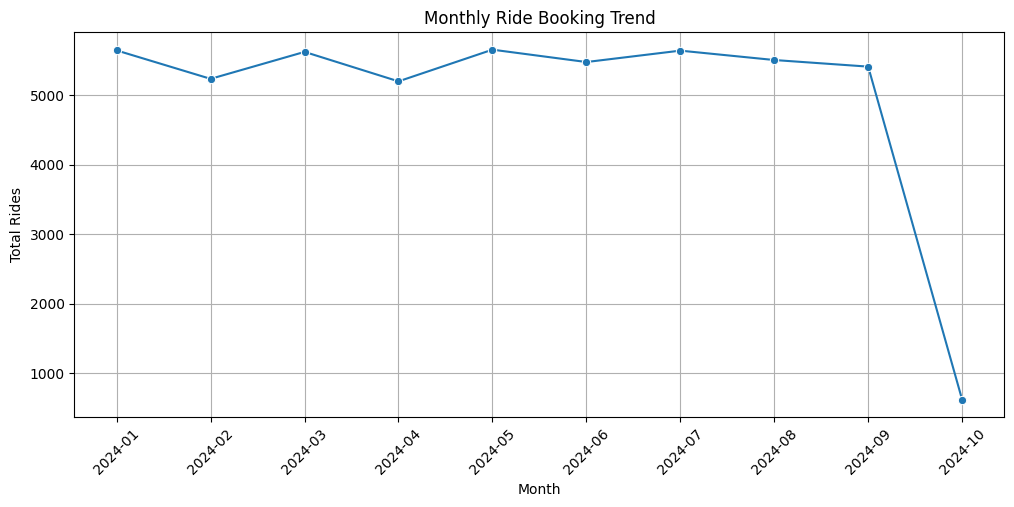

In [21]:
plt.figure(figsize=(12, 5))

monthly_rides = rides.groupby(
    rides['ride_start_time'].dt.to_period('M')
).size()

monthly_rides.index = monthly_rides.index.astype(str)

sns.lineplot(x=monthly_rides.index, y=monthly_rides.values, marker='o')

plt.title("Monthly Ride Booking Trend")
plt.xlabel("Month")
plt.ylabel("Total Rides")
plt.xticks(rotation=45)
plt.grid()
plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\monthly_booking_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

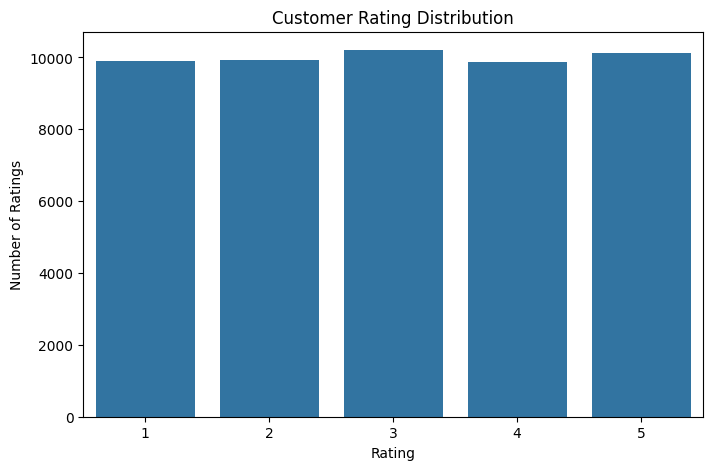

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(data=ratings, x='rating_value')

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\customer_rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

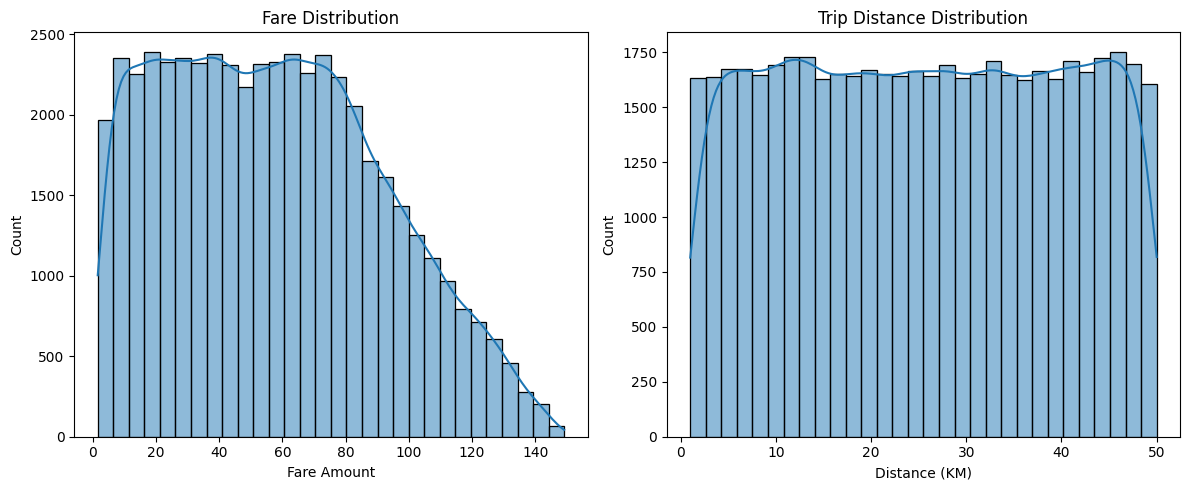

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(rides['fare_amount'], bins=30, kde=True)
plt.title("Fare Distribution")
plt.xlabel("Fare Amount")

plt.subplot(1, 2, 2)
sns.histplot(rides['distance_km'], bins=30, kde=True)
plt.title("Trip Distance Distribution")
plt.xlabel("Distance (KM)")

plt.tight_layout()

plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\fare_and_distance_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

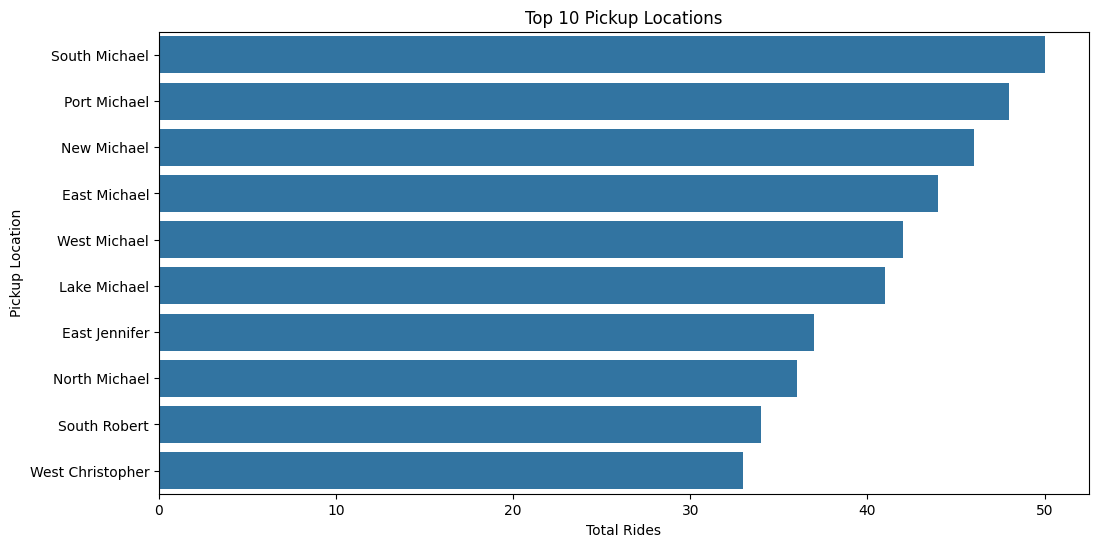

In [27]:
top_locations = location_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_locations,
    x='total_rides',
    y='start_location'
)

plt.title("Top 10 Pickup Locations")
plt.xlabel("Total Rides")
plt.ylabel("Pickup Location")
plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\Top_10_Pickup_Locations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

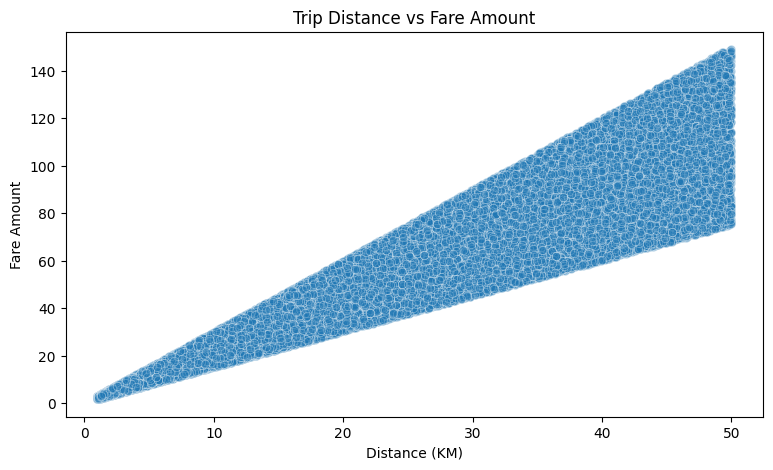

In [30]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rides,
    x='distance_km',
    y='fare_amount',
    alpha=0.4
)

plt.title("Trip Distance vs Fare Amount")
plt.xlabel("Distance (KM)")
plt.ylabel("Fare Amount")
plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\top_10_drivers.png.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

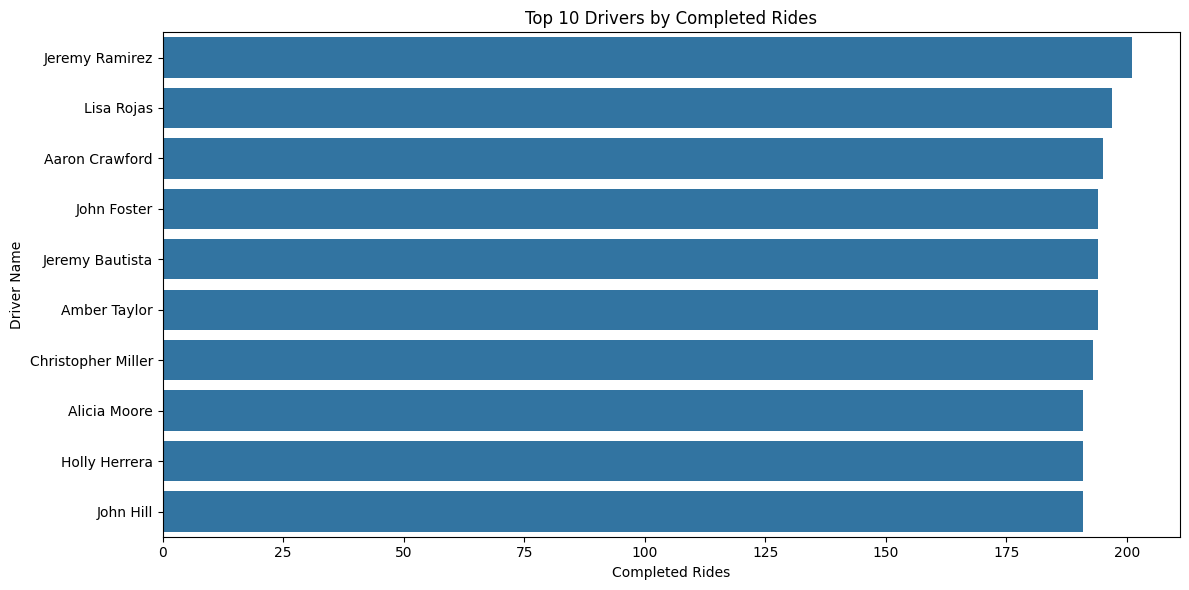

In [31]:
top_drivers = driver_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_drivers,
    x='actual_rides',
    y='name'
)

plt.title("Top 10 Drivers by Completed Rides")
plt.xlabel("Completed Rides")
plt.ylabel("Driver Name")

plt.tight_layout()

plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\top_10_drivers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Statistical summary of ride data

ride_summary = rides[['distance_km', 'fare_amount', 'ride_duration_min']].describe()
ride_summary

,distance_km,fare_amount,ride_duration_min
count,50000.000000,50000.000000,50000.000000
mean,25.535241,57.431624,62.456100
std,14.156627,34.260297,33.423844
min,1.000000,1.570000,5.000000
25%,13.220000,28.670000,33.000000
50%,25.540000,55.290000,62.000000
75%,37.890000,82.010000,91.000000
max,50.000000,149.130000,120.000000


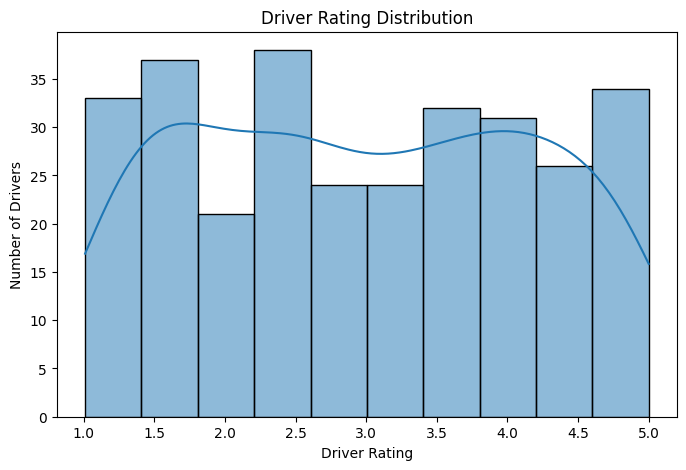

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(data=drivers, x='rating', bins=10, kde=True)

plt.title('Driver Rating Distribution')
plt.xlabel('Driver Rating')
plt.ylabel('Number of Drivers')
plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\driver_rating_distribution.png.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

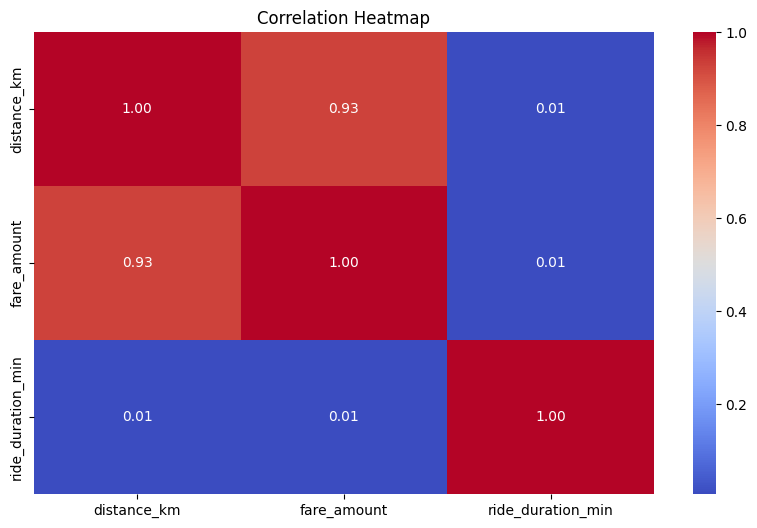

In [35]:
plt.figure(figsize=(10, 6))

corr = rides[['distance_km', 'fare_amount', 'ride_duration_min']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

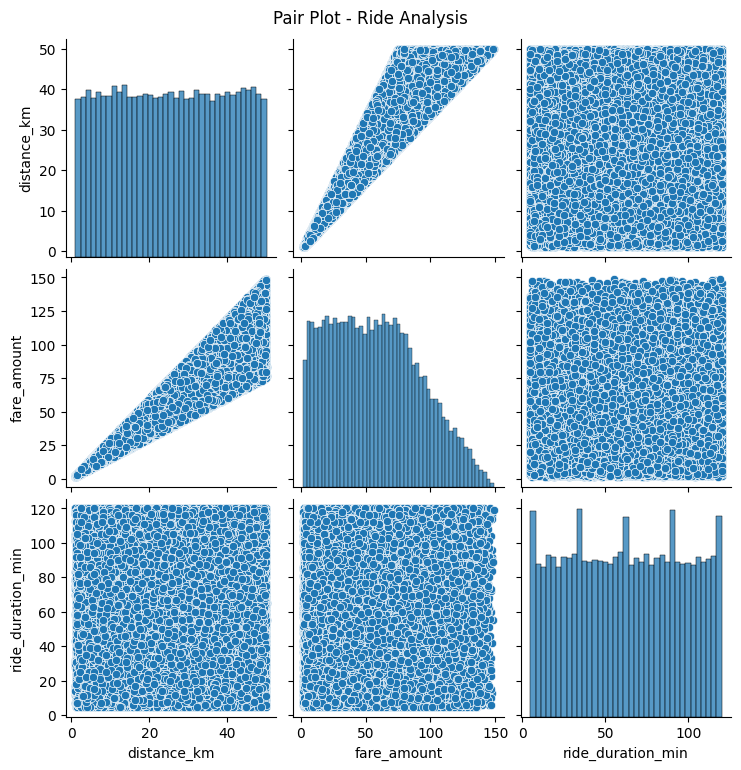

In [40]:
g = sns.pairplot(
    rides[['distance_km', 'fare_amount', 'ride_duration_min']]
)

g.fig.suptitle('Pair Plot - Ride Analysis', y=1.02)

g.savefig(
    r"C:\Users\adity\Theta A\DA Project\report_charts\pair_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Business Insights – Ride Sharing & Cab Booking Analysis
Booking Performance: The dataset contains 50,000 rides, showing the overall booking activity during the analysis period.

Revenue Performance: Total revenue is 2,871,581.19, with an average fare of 57.43 per ride.

Peak Demand: 7 PM is the busiest booking hour, with 2,161 rides. This indicates higher demand during the evening.

Driver Performance: Jeremy Ramirez recorded the highest number of completed rides, with 201 rides.

Customer Ratings: The average customer rating is 3.01 out of 5, indicating scope for improving customer satisfaction.

Pickup Locations: South Michael has the highest number of pickups, with 50 bookings among the analyzed locations.

Trip Analysis: The average trip distance is 25.54 km. Distance and fare analysis can help understand pricing patterns.

Data Limitation: The dataset does not contain cancellation status or payment method information. Therefore, cancellation analysis and payment method distribution could not be performed.

Monthly Trend: October contains data only from October 1 to October 4, so it should not be compared directly with complete months.

Business Recommendations
Improve Evening Availability: Allocate more drivers during the 7 PM peak hour to handle higher booking demand.

Improve Customer Satisfaction: Investigate customer feedback and identify areas where ride experience can be improved.

Monitor Driver Performance: Regularly track driver ratings and completed rides to identify training or improvement opportunities.

Optimize Pricing: Use distance and fare analysis to review pricing patterns and maintain fair fares.

Focus on High-Demand Locations: Monitor pickup demand in locations such as South Michael and Port Michael to improve driver allocation.

Improve Data Collection: Include cancellation status and payment method fields in future datasets to support more detailed business analysis.

In [20]:
print("Rides:", rides.shape)
print("Drivers:", drivers.shape)
print("Users:", users.shape)
print("Vehicles:", vehicles.shape)
print("Ratings:", ratings.shape)

Rides: (50000, 14)
Drivers: (300, 6)
Users: (10000, 8)
Vehicles: (300, 5)
Ratings: (50000, 6)
